# Algoritmo de Aprendizaje por Refuerzo SARSA en Python: Una guía completa

**Fuente original:** https://www.datacamp.com/es/tutorial/sarsa-reinforcement-learning-algorithm-in-python

**Editor y Ejecutor:** Carlos Francisco Montoya Urzua

---

El **aprendizaje por refuerzo** (RL) es un potente paradigma de aprendizaje automático. En la RL, el software —normalmente llamado **agente**— aprende a interactuar con los entornos para resolver problemas complejos mediante ensayo y error, todo ello sin intervención humana. Entre los algoritmos de RL, **SARSA** destaca por su eficacia *en política* (*on-policy*).

**SARSA** significa **Estado–Acción–Recompensa–Estado–Acción**, y representa un ciclo que sigue el agente para resolver problemas. Este ciclo permite al agente aprender de sus errores pasados y aventurarse de vez en cuando a probar cosas nuevas. Este comportamiento hace que el algoritmo sea especialmente eficaz en determinados tipos de problemas y lo diferencia de los algoritmos *sin política* (*off-policy*), como el **Q-Learning**.

En este tutorial aprenderás cómo funciona SARSA y cómo puedes implementarlo en Python. Para concretar tu comprensión, utilizaremos a lo largo de todo el tutorial el clásico problema del **Viaje en Taxi**. También hablaremos de las ventajas, limitaciones y aplicaciones reales de SARSA.

---

<a id='que-es-sarsa'></a>
## 1. ¿Qué es SARSA? La respuesta breve

SARSA, abreviatura de **Estado–Acción–Recompensa–Estado–Acción**, describe una secuencia de acontecimientos en un proceso de aprendizaje. Es un método de aprendizaje eficaz para que los programas informáticos (agentes) tomen buenas decisiones en diversos escenarios.

La idea principal de SARSA es el **ensayo y error**. El agente realiza una acción en una situación, observa el resultado y ajusta su estrategia en función de ese resultado (bueno o malo). Este proceso se repite muchas veces, lo que conduce a mejoras en las decisiones del agente a lo largo del tiempo.

Lo que hace especial a SARSA entre los algoritmos de RL es que **aprende de las elecciones reales que hace el agente**, incluso cuando está probando cosas nuevas. Este enfoque es especialmente útil cuando el camino de aprendizaje es tan importante como el resultado final.

Es como si un robot aprendiera a montar en bicicleta conduciéndola de verdad —con caídas y todo—, en lugar de encontrar el camino más corto de A a B utilizando ruedas de entrenamiento protectoras.

<a id='configurar'></a>
## 2. Configurar tu entorno para el tutorial

En este tutorial, utilizaremos ampliamente **NumPy** y la biblioteca de aprendizaje por refuerzo **Gymnasium**. Mientras que NumPy nos ayudará a escribir el algoritmo SARSA, Gymnasium nos proporciona entornos integrados para probar nuestro trabajo.

Instalaremos las dependencias necesarias directamente en Colab con las siguientes celdas:

In [1]:
# Instalación de dependencias en Google Colab
!pip install "gymnasium[toy-text]" numpy matplotlib moviepy --quiet
!pip install ipywidgets --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 41.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 45.6 MB/s eta 0:00:00


<a id='taxi-v3'></a>
## 3. Explicación del entorno Taxi-V3

A lo largo del tutorial, utilizaremos el entorno **Taxi-v3**, que es un problema clásico de aprendizaje por refuerzo proporcionado por la biblioteca Gymnasium. Simula un taxista que navega por un mundo cuadriculado de **5×5** para recoger y dejar pasajeros.

Para cargar el entorno, utilizamos el método `.make()` de Gymnasium con el modo de renderizado `rgb_array` (para visualizar el entorno más adelante):

In [33]:
import gymnasium as gym

env = gym.make('Taxi-v4', render_mode='rgb_array')

Recordando que ahora se utiliza 'Taxi-v4' en lugar de 'Taxi-v3'

El entorno es una cuadrícula de 5×5 con cuatro ubicaciones designadas: **rojo (R)**, **verde (G)**, **amarillo (Y)** y **azul (B)**. El taxi parte de una casilla aleatoria y debe recoger a un pasajero en uno de los lugares de color y dejarlo en otro.

El taxi puede moverse hacia el Norte, Sur, Este u Oeste, y también puede intentar recoger o dejar a un pasajero.

Así podemos visualizar el estado inicial del entorno con Matplotlib:

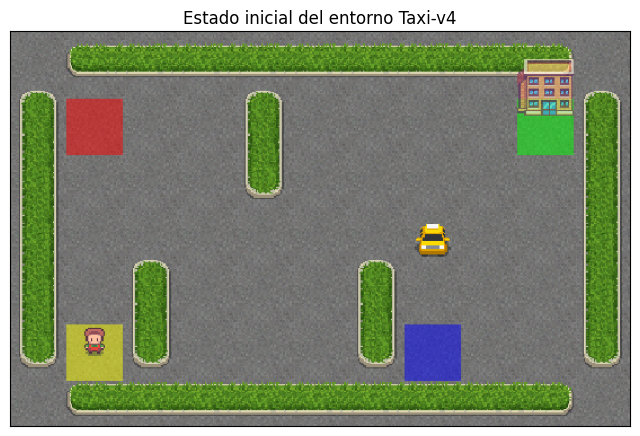

In [34]:
import matplotlib.pyplot as plt

# Reiniciamos el entorno para obtener un estado inicial
# Cada vez que reiniciamos, obtenemos un nuevo estado aleatorio
initial_state, _ = env.reset()

# Renderizamos el estado inicial
img = env.render()

# Creamos la figura y mostramos el entorno
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(img)

# Eliminamos las marcas de los ejes
ax.set_xticks([])
ax.set_yticks([])
plt.title("Estado inicial del entorno Taxi-v4")
plt.show()

Primero reiniciamos el entorno para obtener un estado inicial. Luego mostramos ese estado con la función `render()`, que devuelve una matriz de imagen NumPy. La función `imshow()` de Matplotlib toma esa matriz y produce una visualización limpia sin marcas en los ejes.

Tómate un momento para comprender la disposición del mundo cuadriculado de Taxi-v3, fijándote en la posición del taxi, las barreras, la ubicación de los pasajeros y el destino.

El agente (el taxi) recibe:
- **+20 puntos** por dejar con éxito a un pasajero.
- **-10 puntos** por recoger o dejar en un lugar incorrecto.
- **-1 punto** en cada paso temporal para animar al taxi a completar la tarea rápidamente.

Un episodio finaliza cuando el taxi deja exitosamente al pasajero o se alcanza el número máximo de pasos temporales.

In [35]:
# Número de estados y acciones
n_states = env.observation_space.n
n_actions = env.action_space.n

print("Número de estados:", n_states)
print("Número de acciones:", n_actions)

Número de estados: 500
Número de acciones: 6


Hay **500 estados** en el espacio de estados del entorno. Cada estado está representado por:

- Fila del taxi (0–4)
- Columna del taxi (0–4)
- Ubicación del pasajero (0–3 para R, G, Y, B; o 4 si está dentro del taxi)
- Lugar de destino (0–3 para R, G, Y, B)

**Total de estados** = 5 (filas) × 5 (columnas) × 5 (ubicaciones del pasajero) × 4 (destinos) = **500**

Los **códigos de acción** son:

| Código | Acción |
|--------|--------|
| 0 | Moverse hacia el Sur |
| 1 | Moverse hacia el Norte |
| 2 | Moverse hacia el Este |
| 3 | Moverse hacia el Oeste |
| 4 | Recoger al pasajero |
| 5 | Dejar al pasajero |

El objetivo es que el agente aprenda una **política óptima** para maximizar su recompensa total recogiendo y dejando pasajeros de forma eficiente.

<a id='bucle-interaccion'></a>
## 4. Bucle de Interacción SARSA

Antes de escribir el algoritmo completo, veamos cómo funciona el ciclo **Estado–Acción–Recompensa–Estado–Acción** utilizando nuestro entorno.

Primero, definimos cuántos episodios queremos que continúe la interacción. Un **episodio** representa una ejecución completa de la tarea del taxi, desde el estado inicial hasta que se consigue dejar al pasajero o se alcanza el número máximo de pasos temporales. Cada episodio permite al agente aprender de sus experiencias y mejorar su estrategia con el tiempo.

In [36]:
n_episodes = 10000
#ORIGINALMENTE ERAN 5000

Ahora escribimos el bucle de interacción:

In [37]:
import numpy as np

for episode in range(n_episodes):
    state, _ = env.reset()
    done = False
    total_reward = 0
    steps = 0

    while not done:
        # Elegimos una acción aleatoria
        action = env.action_space.sample()

        # Tomamos la acción y observamos el resultado
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        # Actualizamos la recompensa total y el conteo de pasos
        total_reward += reward
        steps += 1

        # Avanzamos al siguiente estado
        state = next_state

    if episode % 1000 == 0:
        print(f"Episodio {episode}, Recompensa Total: {total_reward}, Pasos: {steps}")

Episodio 0, Recompensa Total: -767, Pasos: 200
Episodio 1000, Recompensa Total: -722, Pasos: 200
Episodio 2000, Recompensa Total: -839, Pasos: 200
Episodio 3000, Recompensa Total: -695, Pasos: 200
Episodio 4000, Recompensa Total: -749, Pasos: 200
Episodio 5000, Recompensa Total: -776, Pasos: 200
Episodio 6000, Recompensa Total: -821, Pasos: 200
Episodio 7000, Recompensa Total: -731, Pasos: 200
Episodio 8000, Recompensa Total: -875, Pasos: 200
Episodio 9000, Recompensa Total: -641, Pasos: 200


El código anterior demuestra el ciclo básico de interacción SARSA **sin implementar ningún algoritmo de aprendizaje**:

1. Reinicia el entorno al comienzo de cada episodio — **(S)**, `env.reset()`.
2. Realiza una acción aleatoria — **(A)**, `env.step(action)`. Esta versión utiliza acciones aleatorias para demostrar el bucle de interacción.
3. Recibe la recompensa **(R)** y el siguiente estado **(S')**, `next_state`, `reward`.
4. Realiza la acción **(A')** en el nuevo estado.

En el bucle anterior, el taxi sigue moviéndose por el entorno en todas direcciones realizando acciones aleatorias hasta que se agotan los pasos de tiempo.

<a id='animacion'></a>
## 5. Animación del Bucle de Interacción SARSA

Antes de continuar, vamos a implementar una función para **animar** nuestros bucles de interacción. Esto nos permite ver visualmente al taxi interactuando con el entorno.

Crear la animación será un proceso sencillo:

- En cada paso temporal, capturamos el estado del entorno en una **matriz de imagen** usando `env.render()`.
- Recogemos las matrices en una variable separada.
- Usando la librería `moviepy`, concatenamos todas las matrices para crear un único GIF.

Modifiquemos el código:

In [38]:
env = gym.make("Taxi-v4", render_mode="rgb_array")
n_episodes = 1
frames = []  # para la animación

for episode in range(n_episodes):
    # Reiniciamos el entorno
    state, _ = env.reset()

    # Capturamos el estado como imagen
    img = env.render()
    frames.append(img)

    done = False
    total_reward = 0
    steps = 0

    while not done:
        # Elegimos una acción aleatoria
        action = env.action_space.sample()

        # Tomamos la acción y observamos el resultado
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        # Capturamos el siguiente estado como imagen
        img = env.render()
        frames.append(img)

        # Actualizamos la recompensa total y el conteo de pasos
        total_reward += reward
        steps += 1

        # Avanzamos al siguiente estado
        state = next_state

En esta versión fijamos el número de episodios en solo **uno**, ya que renderizar los estados del entorno como imágenes lleva demasiado tiempo. También creamos una lista vacía para almacenar nuestras matrices de imágenes. El bucle de interacción continúa como antes; la única diferencia son las dos líneas adicionales donde renderizamos el entorno y lo añadimos a `frames`.

Ahora debemos tener 201 imágenes dentro de `frames` (una imagen extra para el estado inicial):

In [39]:
print("Número de fotogramas capturados:", len(frames))

Número de fotogramas capturados: 201


Convirtamos estas imágenes en un GIF utilizando la librería `moviepy`:

In [40]:
from moviepy.editor import ImageSequenceClip

def create_gif(frames: list, filename, fps=5):
    """
    Crea una animación GIF a partir de una lista de arrays NumPy RGBA.

    Args:
        frames: Lista de arrays NumPy RGBA que representan los fotogramas.
        filename: Nombre del archivo de salida para el GIF.
        fps: Fotogramas por segundo de la animación (por defecto: 5).
    """
    clip = ImageSequenceClip(frames, fps=fps)
    clip.write_gif(filename, fps=fps)

# Ejemplo de uso: guarda el GIF localmente
create_gif(frames, "animacion_aleatoria.gif", fps=25)
print("GIF guardado como 'animacion_aleatoria.gif'")

MoviePy - Building file animacion_aleatoria.gif with imageio.


GIF guardado como 'animacion_aleatoria.gif'


La función `create_gif()` toma una lista de fotogramas y los convierte en un GIF usando la clase `ImageSequenceClip` de `moviepy`. Un parámetro importante es `fps` (fotogramas por segundo), que controla la duración del GIF: a más fotogramas por segundo, más corto el GIF.

Como puedes ver, el taxi no tiene ni idea de lo que hace y ni siquiera se acercó al pasajero. **Démosle un poco de cerebro** añadiendo SARSA a su sistema de navegación.

<a id='implementacion'></a>
## 6. Implementar SARSA en Python Paso a Paso

Construiremos el código de SARSA desde cero para que recuerdes cada paso con claridad.

---

### Paso 1: Configurar el entorno Gymnasium

In [13]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

# Creamos el entorno Taxi
env = gym.make("Taxi-v4", render_mode="rgb_array")

### Paso 2: Inicializar una Tabla Q

In [14]:
# Inicializamos la tabla Q
n_states = env.observation_space.n
n_actions = env.action_space.n
Q_table = np.zeros((n_states, n_actions))

En este paso introducimos una nueva estructura de datos: la **tabla Q**. Tiene las dimensiones `(número de estados) × (número de acciones)`. Inicialmente se rellena con ceros:

In [15]:
print("Forma de la tabla Q:", Q_table.shape)

Forma de la tabla Q: (500, 6)


Después, cuando el agente empiece a interactuar con el entorno guiado por SARSA, actualizará la tabla Q con los **valores Q**. Los valores Q son puntuaciones que indican al agente qué acción es la mejor que puede realizar, dado el estado actual.

---

### Paso 3: Definir los Hiperparámetros de SARSA

Tras inicializar la tabla Q, fijamos los hiperparámetros de SARSA en valores comunes (hablaremos de ellos más adelante):

In [16]:
# Parámetros de SARSA
alpha = 0.1    # Tasa de aprendizaje
gamma = 0.99   # Factor de descuento
epsilon = 0.1  # Tasa de exploración para la política epsilon-greedy
n_episodes = 20000

### Paso 4: Definir el Almacenamiento para las Métricas de Rendimiento

A continuación, definimos dos listas para almacenar las métricas de rendimiento: la recompensa total y el número de pasos temporales de cada episodio. El objetivo del agente es recoger la mayor cantidad de recompensa posible en el menor tiempo posible:

In [17]:
# Listas para almacenar métricas de rendimiento
episode_rewards = []
episode_lengths = []

### Paso 5: Política Epsilon-Greedy para Tomar Acciones

En la sección anterior, nuestro agente no estaba guiado: realizaba acciones aleatorias. Queremos cambiar eso dándole al conductor una estrategia **Epsilon-Greedy**:

In [18]:
def epsilon_greedy(state, epsilon):
    if np.random.random() < epsilon:
        # Acción aleatoria — exploración
        return env.action_space.sample()
    else:
        # Acción con el mayor valor Q — explotación
        return np.argmax(Q_table[state])

Esta estrategia pretende controlar el **equilibrio crucial entre exploración y explotación**. Con probabilidad `epsilon`, el agente explora el entorno realizando una acción aleatoria; con probabilidad `1-epsilon`, explota su conocimiento actual eligiendo la acción con el valor Q más alto. Este enfoque permite al agente descubrir nuevas estrategias —potencialmente mejores— a la vez que utiliza lo que ya ha aprendido.

---

### Paso 6: Escribir el Bucle de Entrenamiento SARSA

Por último, escribimos el bucle de entrenamiento SARSA. El principio del bucle ya nos es familiar. La única diferencia es que usamos la función `epsilon_greedy()` para saber qué acción realizar en el estado actual:

In [19]:
# Inicio del bucle de entrenamiento SARSA
for episode in range(n_episodes):
    state, _ = env.reset()
    action = epsilon_greedy(state, epsilon)
    done = False
    total_reward = 0
    steps = 0
    # (el bucle while se completa abajo)
    break  # celda de demostración; el bucle completo está más adelante

A continuación, iniciamos el bucle `while` que nos permite ejecutar el ciclo de interacción hasta alcanzar un estado de terminación:

In [20]:
# Fragmento ilustrativo — bucle while interno
# (dentro del for episode in range(n_episodes):)
#
# while not done:
#     next_state, reward, terminated, truncated, _ = env.step(action)
#     done = terminated or truncated
#     next_action = epsilon_greedy(next_state, epsilon)
print("Estructura del bucle while ilustrada arriba como comentario.")

Estructura del bucle while ilustrada arriba como comentario.


Dentro del bucle `while`, tomamos la acción devuelta por `epsilon_greedy()` y recibimos el siguiente estado, la recompensa por nuestra acción y un valor booleano para saber si el episodio ha terminado.

A continuación llegamos a la parte crucial: la **regla de actualización de SARSA**:

$$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ R + \gamma \cdot Q(s', a') - Q(s, a) \right]$$

Aprenderemos la intuición detrás de esta fórmula en una sección posterior. Por ahora, considera la fórmula como la magia matemática que actualiza los valores Q de nuestra tabla Q según las reglas de SARSA.

Una vez realizada la actualización Q, cambiamos `state` y `action` por el estado y la acción resultantes, añadimos la recompensa recibida a la recompensa total del episodio y aumentamos el número de pasos temporales.

El bucle `while` continúa hasta alcanzar el máximo de pasos de tiempo (200 para el entorno del taxi) o cuando el taxi deja con éxito al pasajero.

Una vez finalizado el bucle, registramos la recompensa total por episodio y la duración del episodio, e imprimimos las medias cada 2000 episodios.

Aquí tienes el **bucle de entrenamiento completo** ejecutado:

In [21]:
# Reiniciamos la tabla Q y métricas para el entrenamiento completo
Q_table = np.zeros((n_states, n_actions))
episode_rewards = []
episode_lengths = []

# Bucle de entrenamiento SARSA
for episode in range(n_episodes):
    state, _ = env.reset()
    action = epsilon_greedy(state, epsilon)
    done = False
    total_reward = 0
    steps = 0

    while not done:
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        next_action = epsilon_greedy(next_state, epsilon)

        # Regla de actualización SARSA
        Q_table[state, action] += alpha * (
            reward + gamma * Q_table[next_state, next_action] - Q_table[state, action]
        )

        state = next_state
        action = next_action
        total_reward += reward
        steps += 1

    episode_rewards.append(total_reward)
    episode_lengths.append(steps)

    if episode % 2000 == 0:
        avg_reward = np.mean(episode_rewards[-1000:])
        avg_length = np.mean(episode_lengths[-1000:])
        print(f"Episodio {episode}, Recompensa Media: {avg_reward:.2f}, Duración Media: {avg_length:.2f}")

Episodio 0, Recompensa Media: -740.00, Duración Media: 200.00
Episodio 2000, Recompensa Media: -5.40, Duración Media: 19.97
Episodio 4000, Recompensa Media: 2.82, Duración Media: 14.68
Episodio 6000, Recompensa Media: 2.06, Duración Media: 14.81
Episodio 8000, Recompensa Media: 1.77, Duración Media: 14.94
Episodio 10000, Recompensa Media: 2.37, Duración Media: 14.72
Episodio 12000, Recompensa Media: 2.65, Duración Media: 14.71
Episodio 14000, Recompensa Media: 2.35, Duración Media: 14.88
Episodio 16000, Recompensa Media: 2.08, Duración Media: 14.75
Episodio 18000, Recompensa Media: 2.27, Duración Media: 14.70


Como puedes ver en el resultado, la recompensa media y el número de pasos temporales por episodio disminuyeron drásticamente a medida que ejecutábamos más y más episodios.

Podemos comprobarlo visualmente trazando las curvas de `episode_rewards` y `episode_lengths`:

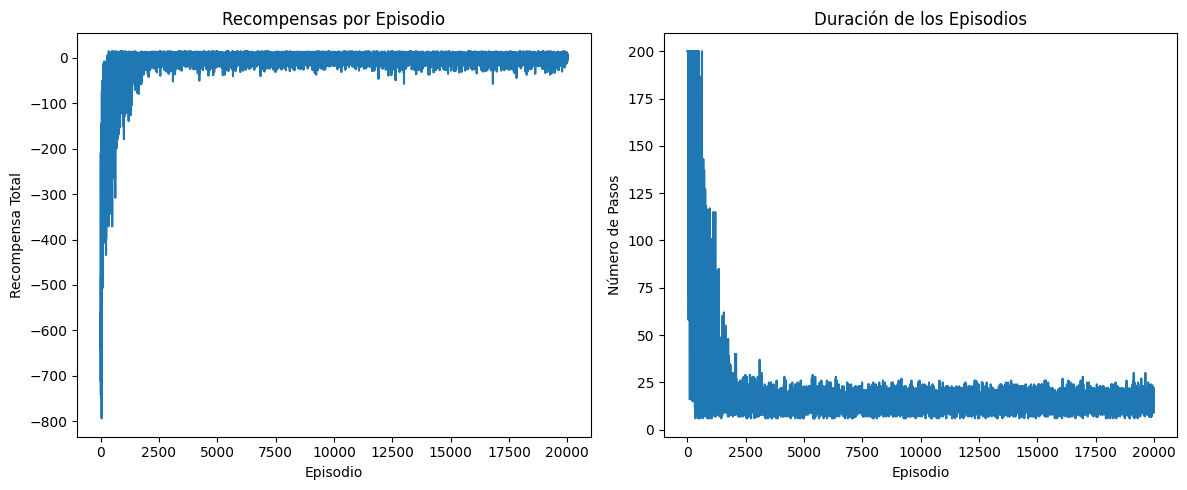

In [22]:
# Trazamos la curva de aprendizaje
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(episode_rewards)
plt.title("Recompensas por Episodio")
plt.xlabel("Episodio")
plt.ylabel("Recompensa Total")

plt.subplot(1, 2, 2)
plt.plot(episode_lengths)
plt.title("Duración de los Episodios")
plt.xlabel("Episodio")
plt.ylabel("Número de Pasos")

plt.tight_layout()
plt.show()

El **gráfico de la izquierda** muestra la recompensa total obtenida en cada episodio:
- Inicialmente, las recompensas son bajas y muy variables, lo que indica que el agente está explorando y aprendiendo.
- Con el tiempo, hay una **tendencia al alza** en las recompensas, lo que sugiere que el agente está mejorando su política.
- Hacia el final, las recompensas parecen estabilizarse en un nivel superior.

El **gráfico de la derecha** muestra el número de pasos dados en cada episodio:
- Al principio, los episodios tienden a ser más largos, ya que el agente realiza acciones subóptimas.
- A medida que avanza el aprendizaje, hay una **tendencia general a la baja** en la duración de los episodios.
- La duración acaba estabilizándose, lo que sugiere que el agente ha aprendido a completar la tarea de forma más eficiente.

<a id='funciones'></a>
## 7. Organizar el Código en Funciones

En poco tiempo hemos cubierto mucho terreno. Demos ahora un paso atrás y organicemos todo lo que hemos escrito. Crearemos funciones para cada uno de los pasos que dimos para implementar SARSA.

En primer lugar, una función para **crear un entorno**:

In [24]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from moviepy.editor import ImageSequenceClip

def create_environment(env_name="Taxi-v4", render_mode="rgb_array"):
    """Crea y devuelve un entorno de Gymnasium."""
    return gym.make(env_name, render_mode=render_mode)

A continuación, una función para **inicializar una tabla Q** dado un entorno:

In [25]:
def initialize_q_table(env):
    """Inicializa y devuelve una tabla Q para el entorno dado."""
    n_states = env.observation_space.n
    n_actions = env.action_space.n
    return np.zeros((n_states, n_actions))

La **estrategia Epsilon-Greedy** que acepta un entorno, una tabla Q, el estado actual y epsilon:

In [26]:
def epsilon_greedy(env, Q_table, state, epsilon=0.1):
    """Selección de acciones epsilon-greedy."""
    if np.random.random() < epsilon:
        return env.action_space.sample()
    else:
        return np.argmax(Q_table[state])

La **regla de actualización de SARSA**, que requiere una tabla Q, el estado actual, la acción realizada, la recompensa, y el estado y la acción siguientes:

In [27]:
def sarsa_update(Q_table, state, action, reward, next_state, next_action, alpha, gamma):
    """Aplica la actualización SARSA sobre la tabla Q."""
    Q_table[state, action] += alpha * (
        reward + gamma * Q_table[next_state, next_action] - Q_table[state, action]
    )

Una gran función para **entrenar al agente con SARSA** que requiere un entorno, el número de episodios y los parámetros alfa, gamma y épsilon:

In [28]:
def train_sarsa(env, n_episodes=20000, alpha=0.1, gamma=0.99, epsilon=0.1):
    """Entrena al agente usando el algoritmo SARSA."""
    Q_table = initialize_q_table(env)
    episode_rewards = []
    episode_lengths = []

    for episode in range(n_episodes):
        state, _ = env.reset()
        action = epsilon_greedy(env, Q_table, state, epsilon)
        done = False
        total_reward = 0
        steps = 0

        while not done:
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            next_action = epsilon_greedy(env, Q_table, next_state, epsilon)
            sarsa_update(
                Q_table, state, action, reward, next_state, next_action, alpha, gamma
            )
            state = next_state
            action = next_action
            total_reward += reward
            steps += 1

        episode_rewards.append(total_reward)
        episode_lengths.append(steps)

    return Q_table, episode_rewards, episode_lengths

Además, una función para **trazar métricas de rendimiento**:

In [29]:
def plot_learning_curve(episode_rewards, episode_lengths):
    """Traza la curva de aprendizaje."""
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(episode_rewards)
    plt.title("Recompensas por Episodio")
    plt.xlabel("Episodio")
    plt.ylabel("Recompensa Total")

    plt.subplot(1, 2, 2)
    plt.plot(episode_lengths)
    plt.title("Duración de los Episodios")
    plt.xlabel("Episodio")
    plt.ylabel("Número de Pasos")

    plt.tight_layout()
    plt.show()

Nuestra función `create_gif()` anterior:

In [30]:
def create_gif(frames, filename, fps=5):
    """Crea una animación GIF a partir de una lista de fotogramas."""
    clip = ImageSequenceClip(frames, fps=fps)
    clip.write_gif(filename, fps=fps)

Y una función para **ejecutar un único episodio** con renderizado usando la tabla Q aprendida (con fines de animación):

In [31]:
def run_episode(env, Q_table, epsilon=0):
    """Ejecuta un único episodio usando la tabla Q aprendida."""
    state, _ = env.reset()
    done = False
    total_reward = 0
    frames = [env.render()]

    while not done:
        action = epsilon_greedy(env, Q_table, state, epsilon)
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        frames.append(env.render())
        total_reward += reward
        state = next_state

    return frames, total_reward

Ahora, vamos a **ejecutarlo todo**:

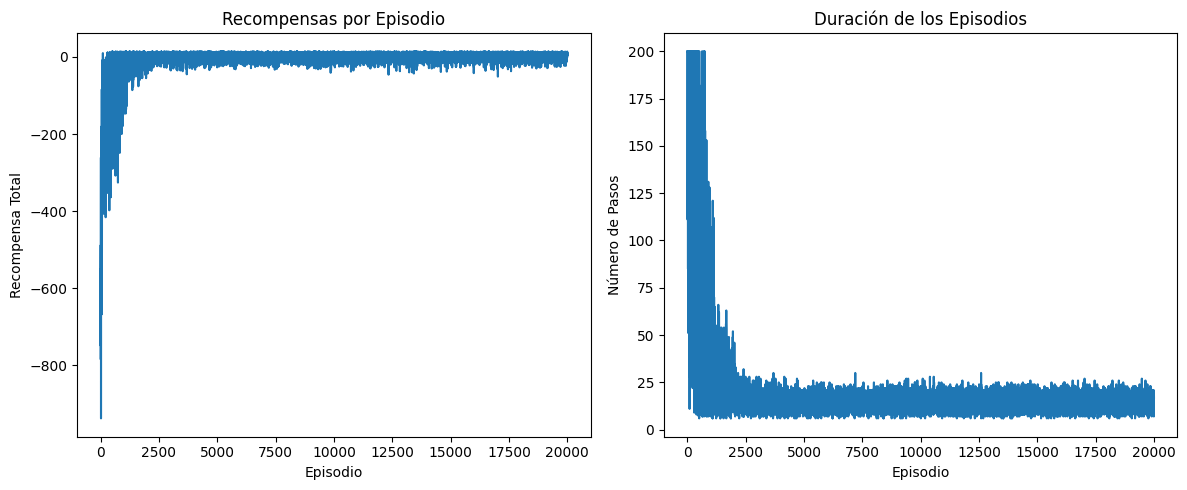

Recompensa total del episodio final: 7
MoviePy - Building file sarsa_animacion_final.gif with imageio.


GIF guardado como 'sarsa_animacion_final.gif'


In [32]:
# Ejecutamos el pipeline completo
env = create_environment()

Q_table, episode_rewards, episode_lengths = train_sarsa(env, n_episodes=20000)
plot_learning_curve(episode_rewards, episode_lengths)

frames, total_reward = run_episode(env, Q_table)
print(f"Recompensa total del episodio final: {total_reward}")
create_gif(frames, "sarsa_animacion_final.gif", fps=1)
print("GIF guardado como 'sarsa_animacion_final.gif'")

Los gráficos de rendimiento tienen buen aspecto. El taxi recoge correctamente al pasajero y lo deja en el destino indicado. ¡Hurra!

<a id='intuicion'></a>
## 8. La Intuición Tras la Regla de Actualización de SARSA

En el corazón de SARSA se encuentra su **regla de actualización**, que controla cómo aprende el agente de sus experiencias. Desglosemos esta regla y exploremos la intuición que hay detrás de ella:

$$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ R + \gamma \cdot Q(s', a') - Q(s, a) \right]$$

---

### Comprender los Componentes

| Símbolo | Significado |
|---------|-------------|
| $Q(s, a)$ | El valor Q actual de realizar la acción $a$ en el estado $s$. |
| $\alpha$ | La **tasa de aprendizaje**: controla la rapidez con que se incorpora la nueva información. |
| $R$ | La **recompensa** recibida tras realizar la acción. |
| $\gamma$ | El **factor de descuento**: determina la importancia de las recompensas futuras. |
| $Q(s', a')$ | El valor Q estimado del **siguiente par estado-acción**. |

---

### El Proceso de Aprendizaje

La regla de actualización de SARSA pretende refinar la comprensión del entorno por parte del agente ajustando los valores Q en función de nuevas experiencias. Funciona así:

1. El agente realiza una acción y observa la recompensa y el siguiente estado.
2. Calcula la diferencia entre su valor Q actual y una nueva estimación basada en la recompensa observada y el valor del siguiente par estado-acción.
3. Esta diferencia, escalada por la tasa de aprendizaje, se usa para actualizar el valor Q.

---

### Error de Diferencia Temporal (TD)

El término $\left[ R + \gamma \cdot Q(s', a') - Q(s, a) \right]$ se conoce como **error de diferencia temporal** (TD). Piensa en ello como una medida de *sorpresa*:

- **Error TD positivo:** El resultado fue *mejor* de lo esperado.
- **Error TD negativo:** El resultado fue *peor* de lo esperado.
- **Error TD cero:** El resultado coincidía perfectamente con la estimación actual.

Este error ayuda al agente a refinar continuamente sus estimaciones, impulsando el proceso de aprendizaje hacia una política óptima.

---

### Papel de los Hiperparámetros

**1. Tasa de aprendizaje ($\alpha$):**
- Controla la velocidad de aprendizaje.
- Mayor $\alpha$: Aprendizaje más rápido, pero potencialmente inestable.
- Menor $\alpha$: Aprendizaje más lento y estable.

**2. Factor de descuento ($\gamma$):**
- Equilibra las recompensas inmediatas y futuras.
- $\gamma$ cercano a 1: El agente valora las recompensas futuras casi tanto como las inmediatas.
- $\gamma$ pequeño: El agente se centra más en las recompensas inmediatas.

**3. Tasa de exploración ($\varepsilon$):**
- Aunque no aparece en la regla de actualización, es crucial para la política epsilon-greedy.
- Equilibra la exploración (probar nuevas acciones) y la explotación (usar acciones buenas conocidas).
- Mayor $\varepsilon$: Más exploración, descubriendo potencialmente mejores estrategias a costa del rendimiento a corto plazo.

---

### Panorama General

La regla de actualización de SARSA permite al agente aprender de sus experiencias ajustando constantemente sus estimaciones de los valores estado-acción. Con cada interacción, el agente se vuelve un poco más sabio sobre su entorno. A lo largo de muchos episodios, este proceso conduce al desarrollo de una **política óptima** para navegar por el entorno.

Afinando los hiperparámetros, podemos controlar varios aspectos del proceso de aprendizaje, lo que permite a SARSA adaptarse a distintos tipos de problemas y entornos. Esta flexibilidad, combinada con su intuitiva regla de actualización, hace de SARSA un algoritmo de aprendizaje por refuerzo potente y muy utilizado.

<a id='sarsa-vs-qlearning'></a>
## 9. SARSA vs. Q-Learning: Diferencias Clave

Aunque SARSA y Q-Learning son algoritmos de aprendizaje por refuerzo muy utilizados, tienen diferencias importantes que son fundamentales para comprender cuándo y cómo usar cada uno.

---

### 1. En Política vs. Sin Política (*On-policy* vs. *Off-policy*)

SARSA es un algoritmo **en política** (*on-policy*): aprende el valor de la política que sigue, incluyendo los pasos exploratorios. Q-Learning es **sin política** (*off-policy*): aprende el valor de la política óptima, incluso cuando no la sigue activamente. Por eso SARSA debe usarse cuando el recorrido de aprendizaje es tan importante como el resultado.

---

### 2. Regla de Actualización

| Algoritmo | Regla de actualización |
|-----------|------------------------|
| **SARSA** | $Q(s,a) \leftarrow Q(s,a) + \alpha\,[R + \gamma\,Q(s',a') - Q(s,a)]$ |
| **Q-Learning** | $Q(s,a) \leftarrow Q(s,a) + \alpha\,[R + \gamma\,\max_{a'}Q(s',a') - Q(s,a)]$ |

La diferencia clave es que SARSA usa el valor Q de la **siguiente acción realmente realizada** ($a'$), mientras que Q-Learning usa el **valor Q máximo** del siguiente estado.

---

### 3. Consideración de la Exploración

Al actualizar los valores Q, **SARSA no ignora la política de exploración** y por tanto es más conservador. Q-Learning siempre supone que el agente realizará la acción óptima en el futuro y es más agresivo.

---

### 4. Convergencia

Aunque ambos algoritmos alcanzan finalmente la política óptima, **Q-Learning a menudo puede aprender más rápidamente**, sobre todo en entornos deterministas.

---

### 5. Seguridad

En entornos en los que la exploración puede conducir a malos resultados, **SARSA tiende a aprender políticas más seguras** porque tiene en cuenta la política real que se sigue.

En el problema clásico de *"caminar por el acantilado"*, SARSA suele aprender un camino más alejado del borde, mientras que Q-Learning puede aprender un camino más arriesgado.

---

### 6. Estabilidad

En ciertos entornos aleatorios, **SARSA puede ser más estable** porque tiene en cuenta la acción siguiente real, incluso cuando es exploratoria.

---

### 7. Sensibilidad de los Hiperparámetros

Q-Learning puede ser más sensible a la elección de la tasa de aprendizaje y la tasa de exploración, especialmente en entornos con significativa estocasticidad.

---

### 8. Aplicaciones en el Mundo Real

| Situación | Algoritmo recomendado |
|-----------|----------------------|
| Robótica y sistemas físicos (exploración costosa, políticas seguras) | **SARSA** |
| Entornos simulados, juegos, alta retroalimentación disponible | **Q-Learning** |

Podrías pensar que SARSA es la opción más segura y conservadora, y Q-Learning es el enfoque más rápido y temerario. En la práctica, depende del problema concreto. Ambos son muy potentes y conocer sus diferencias siempre tiene sentido.

<a id='conclusion'></a>
## 10. Conclusión

En esta guía completa hemos explorado el **algoritmo SARSA**, cubriendo sus conceptos básicos, detalles de implementación y aplicaciones prácticas usando el entorno Taxi-v3.

Los puntos clave son:

1. La naturaleza **en política** (*on-policy*) de SARSA y la intuición de su regla de actualización.
2. Técnicas de **implementación y visualización** en Python.
3. **Comparación con Q-Learning**, destacando los puntos fuertes y los casos de uso de cada uno.

La capacidad de SARSA para aprender políticas más seguras lo hace adecuado para aplicaciones del mundo real en las que los costes de exploración son elevados, aunque puede converger más lentamente que los algoritmos sin políticas como Q-Learning en algunos escenarios.

Recuerda que elegir entre SARSA y otros algoritmos depende de tu problema y entorno específicos. La experimentación y el ajuste son cruciales para obtener resultados óptimos.

---